In [1]:
from reasoning_aware_irt.toy_scenarios import make_reasoning_aware_3pl_toy, build_scenarios

In [2]:
toy_list, names = build_scenarios()
print(names, len(toy_list))

['fail_budget_leverage_items', 'fail_budget_response', 'fail_confounding', 'fail_effective_rank', 'fail_fisher_proxy', 'fail_variance_ceiling', 'fail_variance_floor', 'pass_all'] 8


In [3]:
from reasoning_aware_irt.precondition_check import DataPreChecker
import numpy as np

avg_Y_list = [float(np.mean(t['Y_ij'])) for t in toy_list]

# results_list = []
passes = []
warns = []
all_results = {}
for i, toy in enumerate(toy_list):
    print('\n', names[i])
    chk = DataPreChecker(Y_ij=toy['Y_ij'], B_ij=toy['B_ij'], P_ij=toy.get('P_ij'))
    ok, warn, res = chk.run_all_tests()
    all_results[names[i]] = res
    # results_list.append(res)
    passes.append(ok)
    warns.append(warn)


print("passes:", passes)
print("warns:", warns)


 fail_budget_leverage_items
[PASS] Variance/Entropy: Items=0.74, Models=0.98
[PASS] Fisher Proxy: Items=0.1920, Models=0.2278
[FAIL] Budget Leverage: Items OK=0.20, Models OK=1.00
[PASS] Effective Rank=30.50, Ratio=0.94
[PASS] Ability-Budget Confounding Corr=-0.1017
[WARN] Budget-Response Association: Signal Prop=0.055 with threshold=0.23
[PASS] Budget-Response with PROB: Signal Prop=0.125 with threshold=0.23

 fail_budget_response
[PASS] Variance/Entropy: Items=0.81, Models=1.00
[PASS] Fisher Proxy: Items=0.1965, Models=0.2319
[PASS] Budget Leverage: Items OK=1.00, Models OK=1.00
[PASS] Effective Rank=46.16, Ratio=0.95
[PASS] Ability-Budget Confounding Corr=-0.0919
[PASS] Budget-Response Association: Signal Prop=0.120 with threshold=0.23
[PASS] Budget-Response with PROB: Signal Prop=0.105 with threshold=0.23

 fail_confounding
[PASS] Variance/Entropy: Items=0.74, Models=0.98
[PASS] Fisher Proxy: Items=0.1920, Models=0.2278
[PASS] Budget Leverage: Items OK=1.00, Models OK=1.00
[PASS] 

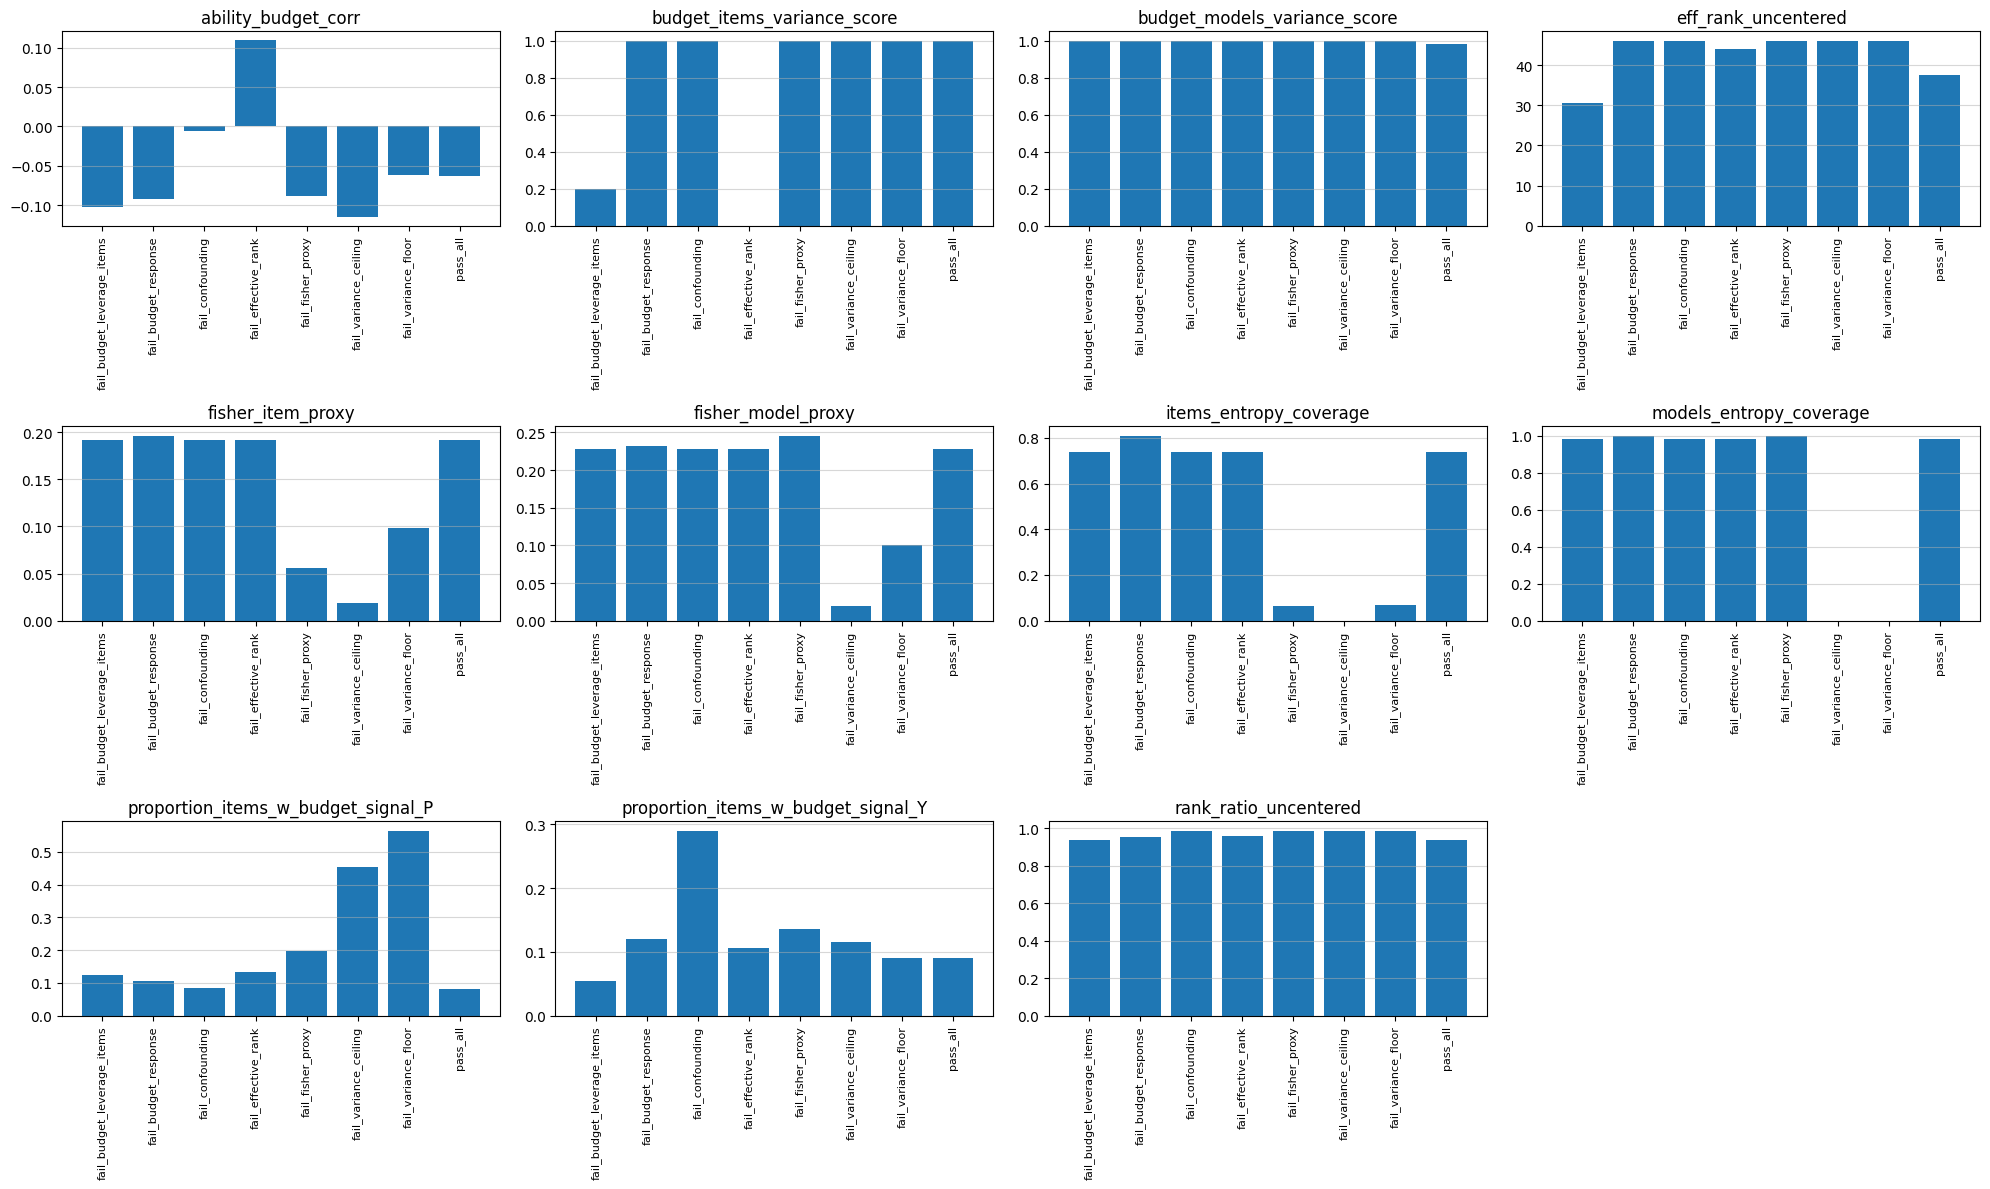

In [4]:
from reasoning_aware_irt.precondition_check import plot_precheck_results
import matplotlib.pyplot as plt
# fig, _ = plot_precheck_results(results_list, titles=names, avg_Y_list=avg_Y_list)
fig, _ = plot_precheck_results(all_results)
plt.show() # enable when running as a script

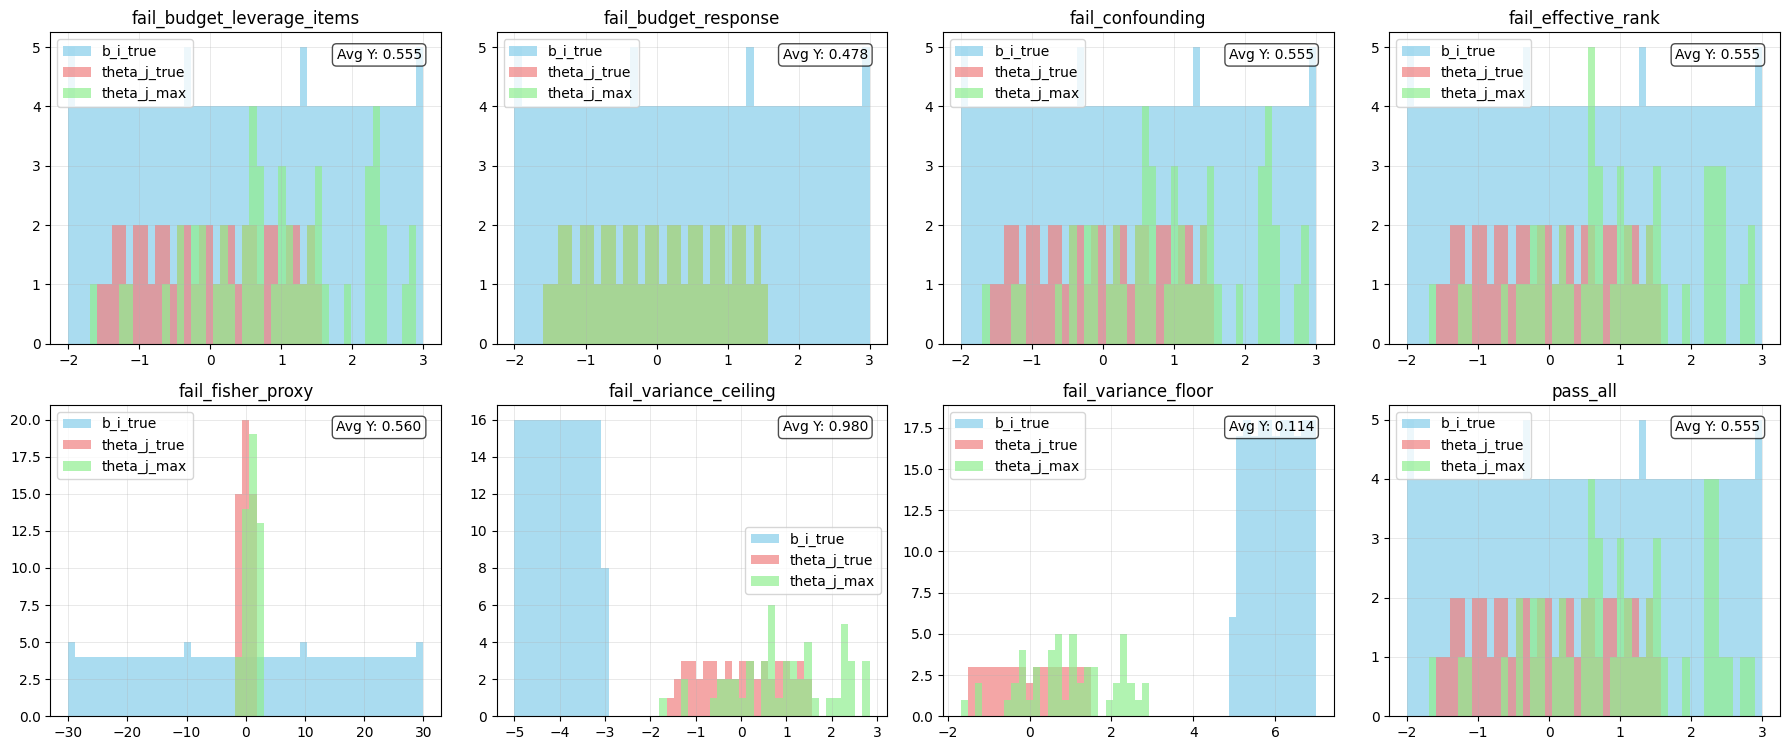

In [5]:
from reasoning_aware_irt.utils import plot_multiple_b_theta_histograms
_, _ = plot_multiple_b_theta_histograms(toy_list, names, plots_per_row=4, avg_Y_list=avg_Y_list)

# Systematic Check - varying #gate-on

In [ ]:
print_msg = False

b_span_list = np.linspace(-2.0, 5, 10)

toy_data_name_list, toy_data_list = [], []
all_results = []
avg_Y_list = []
for b_span in b_span_list:
    toy_data = make_reasoning_aware_3pl_toy(b_span_low=  b_span,
                                           b_span_high= b_span+1,
                                           frac_gate_on=1.0
                                           )
    toy_data_list.append(toy_data)
    toy_data_name_list.append(str(b_span))

    Y_mean = toy_data['Y_ij'].mean()
    avg_Y_list.append(Y_mean)

    if print_msg:
        print(f"\n--- RUNNING b_span: {b_span} ---")
        print(f"Average of Y = {Y_mean}")

    checker = DataPreChecker(Y_ij=toy_data['Y_ij'], B_ij=toy_data['B_ij'], P_ij=toy_data['P_ij'], print_msg=print_msg)
    ok, warn, results = checker.run_all_tests()
    all_results.append(results)

In [ ]:
_, _ = plot_multiple_b_theta_histograms(toy_data_list, toy_data_name_list, plots_per_row=4, avg_Y_list=avg_Y_list)

In [ ]:
_,_ = plot_precheck_results(all_results)

# GEM

0.45755


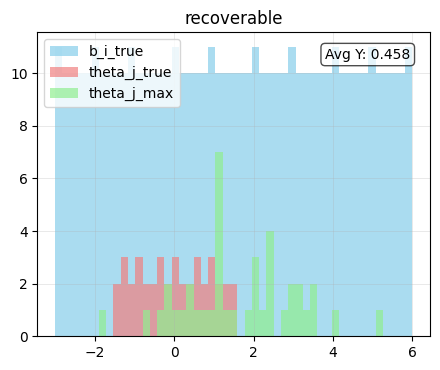

In [6]:
toy_data = make_reasoning_aware_3pl_toy(Q=500, c_val=0.001, 
                                        b_span_low=  -3, b_span_high= 6,frac_gate_on=0.999)

print(toy_data['Y_ij'].mean())
_, _ = plot_multiple_b_theta_histograms([toy_data], ['recoverable'], plots_per_row=2, avg_Y_list=[toy_data['Y_ij'].mean()])

In [7]:
chk = DataPreChecker(Y_ij=toy_data['Y_ij'], B_ij=toy_data['B_ij'], P_ij=toy_data.get('P_ij'))
ok, warn, res = chk.run_all_tests()

[PASS] Variance/Entropy: Items=0.43, Models=1.00
[PASS] Fisher Proxy: Items=0.1320, Models=0.2327
[PASS] Budget Leverage: Items OK=1.00, Models OK=1.00
[PASS] Effective Rank=38.33, Ratio=0.99
[PASS] Ability-Budget Confounding Corr=-0.0666
[PASS] Budget-Response Association: Signal Prop=0.293 with threshold=0.26
[PASS] Budget-Response with PROB: Signal Prop=0.832 with threshold=0.26


In [8]:
from reasoning_aware_irt.gem import CalibrationData, CalibrationConfig
from reasoning_aware_irt.gem import ReasoningAware3PLCalibrator

data = CalibrationData(Y_ij=toy_data["Y_ij"], B_ij=toy_data["B_ij"], c_i=toy_data["c_i_true"])
cfg = CalibrationConfig(
    gh_nodes=100, max_iter=200, verbose=True
)

calibrator = ReasoningAware3PLCalibrator(cfg)


In [9]:
fit_results = calibrator.fit(data)

mu_theta = -1.04, sigma_theta =  1.3076
iter   1  ll=-7090.581704   dLL=nan
mu_theta =  0.00499, sigma_theta =  0.97028
iter   2  ll=-6416.015977   dLL=nan
mu_theta = -0.009, sigma_theta =  0.97714
iter   3  ll=-6245.012922   dLL=1.710e+02
mu_theta = -0.0163, sigma_theta =  0.98257
iter   4  ll=-6193.157697   dLL=5.186e+01
mu_theta = -0.0136, sigma_theta =  0.97849
iter   5  ll=-6163.155904   dLL=3.000e+01
mu_theta = -0.0104, sigma_theta =  0.9742
iter   6  ll=-6143.505393   dLL=1.965e+01
mu_theta = -0.00939, sigma_theta =  0.97503
iter   7  ll=-6127.851830   dLL=1.565e+01
mu_theta = -0.00701, sigma_theta =  0.97508
iter   8  ll=-6114.793109   dLL=1.306e+01
mu_theta = -0.00588, sigma_theta =  0.9816
iter   9  ll=-6103.124289   dLL=1.167e+01
mu_theta = -0.00535, sigma_theta =  0.98401
iter  10  ll=-6090.646347   dLL=1.248e+01
mu_theta = -0.00475, sigma_theta =  0.98344
iter  11  ll=-6081.463864   dLL=9.182e+00
mu_theta = -0.00411, sigma_theta =  0.98519
iter  12  ll=-6073.641182   dLL=7

In [21]:
print('theta correlation:', np.corrcoef( toy_data["theta_j_true"], fit_results.theta_j_mean)[0,1])
print('gamma correlation:', np.corrcoef( toy_data["gamma_j_true"], fit_results.gamma_j)[0,1])
print('b correlation:', np.corrcoef( toy_data["b_i_true"], fit_results.b_i)[0,1])
print('ratio of lambda > 0.6:', (fit_results.lambda_i > 0.6).sum()/ (fit_results.lambda_i.shape[0]))
# print(np.corrcoef( toy_data["theta_j_true"], fit_results.theta_j_mean)[0,1])
# print(np.corrcoef( toy_data["theta_j_true"], fit_results.theta_j_mean)[0,1])

theta correlation: 0.9102073914698773
gamma correlation: 0.8776535539302966
b correlation: 0.807368025430906
ratio of lambda > 0.6: 0.308


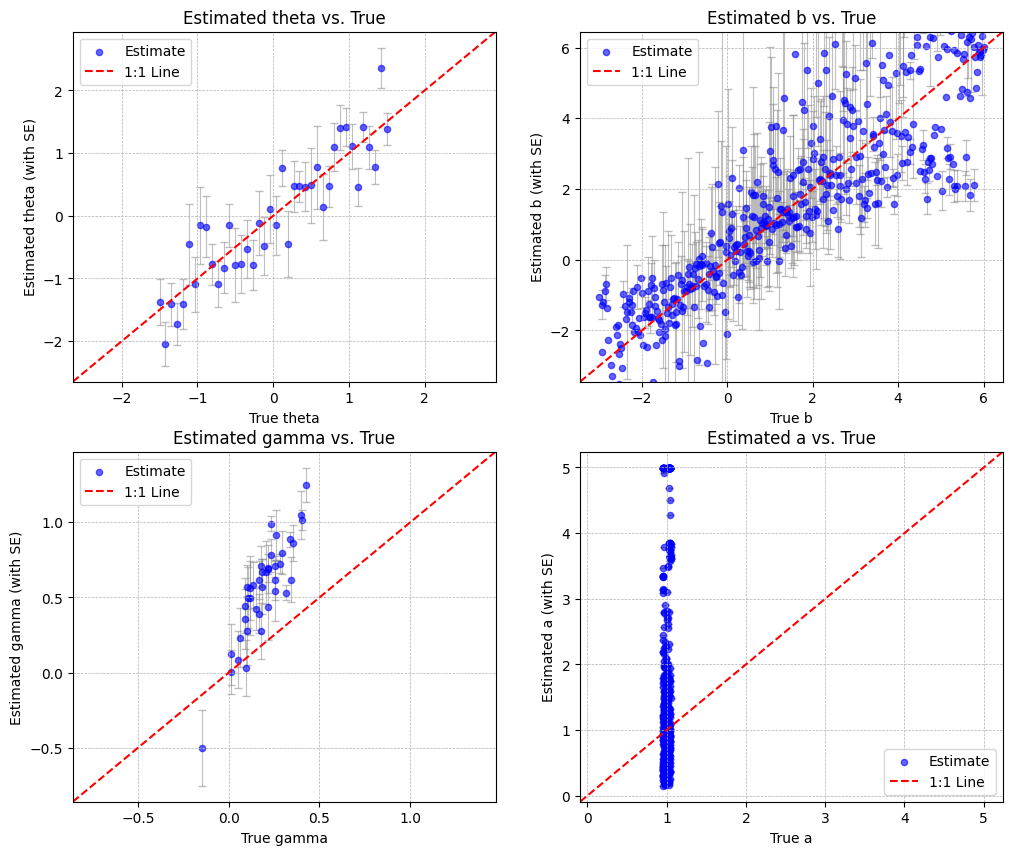

In [16]:
from reasoning_aware_irt.utils import plot_parameter_scatter_with_se

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

plot_parameter_scatter_with_se(axes[0], toy_data["theta_j_true"], fit_results.theta_j_mean, fit_results.theta_bracket_half_tau, "theta")
plot_parameter_scatter_with_se(axes[1], toy_data["b_i_true"], fit_results.b_i, fit_results.b_bracket_half_tau, "b")
plot_parameter_scatter_with_se(axes[2], toy_data["gamma_j_true"], fit_results.gamma_j, fit_results.gamma_bracket_half_tau, "gamma")
plot_parameter_scatter_with_se(axes[3], toy_data["a_i_true"], fit_results.a_i, None, "a")

In [ ]:
from reasoning_aware_irt.gem import compute_laplace_ses
ses = compute_laplace_ses(
        fit_results, data,
        blocks=("a","b","lambda","gamma"),
        ridges={"ridge_a":1e-3,"ridge_b":1e-3,"ridge_lambda":1e-5,"ridge_gamma":1e-5},
    )

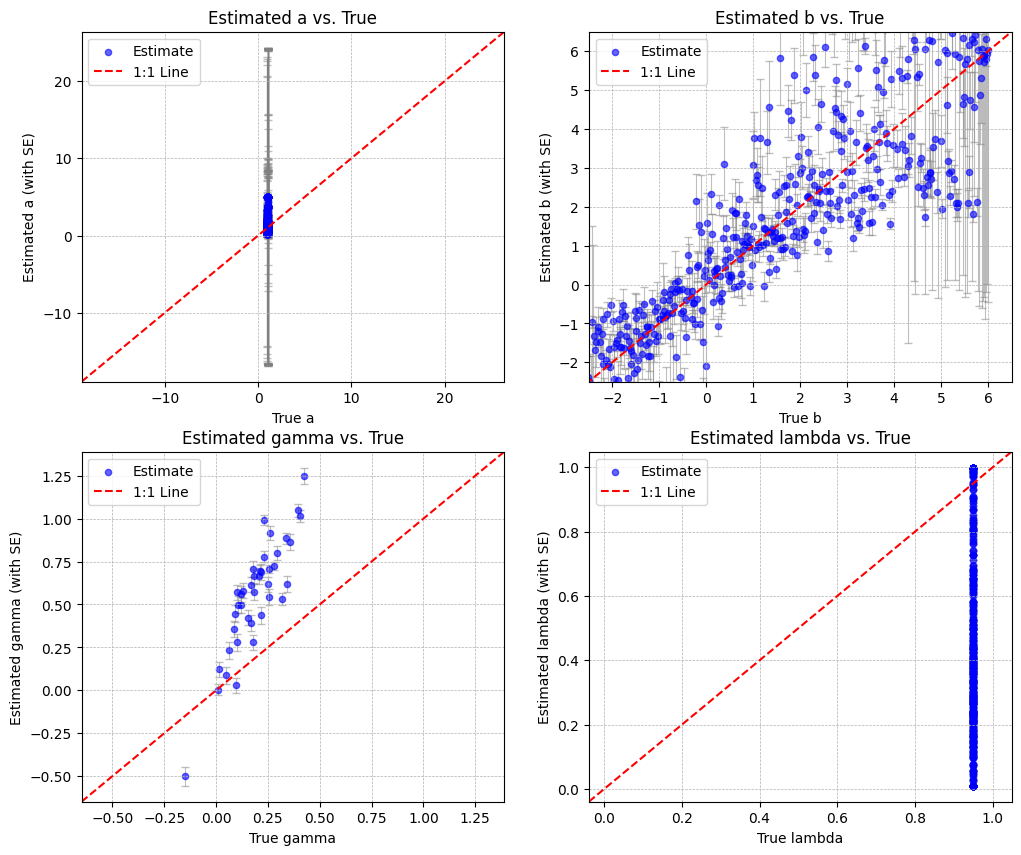

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

plot_parameter_scatter_with_se(axes[0], toy_data["a_i_true"], fit_results.a_i, ses["a_laplace_se"], "a")
plot_parameter_scatter_with_se(axes[1], toy_data["b_i_true"], fit_results.b_i, ses["b_laplace_se"], "b", min_lim = -2.5, max_lim=6.5)
plot_parameter_scatter_with_se(axes[2], toy_data["gamma_j_true"], fit_results.gamma_j, ses["gamma_laplace_se"], "gamma")
plot_parameter_scatter_with_se(axes[3], toy_data["lambda_i_true"], fit_results.lambda_i, None, "lambda")

In [ ]:
# print(fit_results.gamma_bracket_half_ideal)
# print(fit_results.b_bracket_half_ideal)

# print(fit_results.theta_bracket_half_ideal)
# print(fit_results.theta_j_se)

# Macro Information Function

In [ ]:
from reasoning_aware_irt.utils import create_test_information_figure, create_item_information_figure, plot_test_characteristic_curve

item_indices_to_plot = [0, 10, 99, 149, 199]
item_names = [str(i) for i in item_indices_to_plot]

a = np.array([toy_list[-1]['a_i_true'][i] for i in item_indices_to_plot])
b = np.array([toy_list[-1]['b_i_true'][i] for i in item_indices_to_plot])
c = np.array([toy_list[-1]['c_i_true'][i] for i in item_indices_to_plot])

fig = create_test_information_figure(a,b,c,item_names)


In [ ]:
fig.show()

In [ ]:
item_indices_to_plot = [0, 10, 99, 149, 199]
item_names = [str(i) for i in item_indices_to_plot]

a = np.array([toy_list[-1]['a_i_true'][i] for i in item_indices_to_plot])
b = np.array([toy_list[-1]['b_i_true'][i] for i in item_indices_to_plot])
c = np.array([toy_list[-1]['c_i_true'][i] for i in item_indices_to_plot])

fig = create_item_information_figure(a,b,c,item_names)
fig.show()

In [ ]:
fig = plot_test_characteristic_curve(toy_data_list[2])
fig.show()